# Sports Performance: A Visual Exploration of NBA Players

## CodeAlpha Internship — Task 3: Data Visualization

### Project Introduction

This project explores NBA player performance during the 2023–2024 regular season using data visualization.

The goal is to understand scoring, assists, rebounds, and shooting performance through clear and meaningful charts.

### Questions I Want to Explore

1. Which players score the most points?
2. How is scoring distributed among players?
3. What relationship exists between points and assists?
4. How do scoring and rebounding compare?
5. How does scoring differ across teams?
6. What patterns can we discover through visualizations?

### Tools Used

- Python
- Pandas
- Matplotlib
- Seaborn
- Jupyter Notebook

In [1]:

import pandas as pd

url = "https://raw.githubusercontent.com/annlntv/sg_da/main/NBA_2024_cleaned.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (3621, 29)


,Player,Pos,Age,Tm,G,GS,MP,FG,FGA,FG%,...,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,Precious Achiuwa,C,24,TOR,6,0,20.0,3.2,7.3,0.432,...,1.000,2.0,4.2,6.2,1.7,0.2,0.5,1.5,2.2,7.5
1,Bam Adebayo,C,26,MIA,10,10,34.7,8.4,16.0,0.525,...,0.803,2.3,8.2,10.5,3.8,1.4,1.4,2.9,2.3,23.0
2,Ochai Agbaji,SG,23,UTA,11,3,17.2,1.7,4.4,0.396,...,0.500,0.8,1.9,2.7,1.0,0.4,0.6,0.6,1.3,4.5
3,Santi Aldama,PF,23,MEM,5,0,21.0,4.6,9.6,0.479,...,0.444,0.6,4.0,4.6,1.8,0.4,0.8,1.6,1.2,11.6
4,Nickeil Alexander-Walker,SG,25,MIN,11,2,19.9,1.9,4.8,0.396,...,0.333,0.1,1.7,1.8,2.4,0.8,0.8,0.9,1.5,5.0


In [2]:
print("Dataset Information:")
df.info()

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values in Each Column:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 3621 entries, 0 to 3620
Data columns (total 29 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Player  3621 non-null   str    
 1   Pos     3621 non-null   str    
 2   Age     3621 non-null   int64  
 3   Tm      3621 non-null   str    
 4   G       3621 non-null   int64  
 5   GS      3621 non-null   int64  
 6   MP      3621 non-null   float64
 7   FG      3621 non-null   float64
 8   FGA     3621 non-null   float64
 9   FG%     3621 non-null   float64
 10  3P      3621 non-null   float64
 11  3PA     3621 non-null   float64
 12  3P%     3621 non-null   float64
 13  2P      3621 non-null   float64
 14  2PA     3621 non-null   float64
 15  2P%     3621 non-null   float64
 16  eFG%    3621 non-null   float64
 17  FT      3621 non-null   float64
 18  FTA     3621 non-null   float64
 19  FT%     3621 non-null   float64
 20  ORB     3621 non-null   float64
 21  DRB     3621 non-null   flo

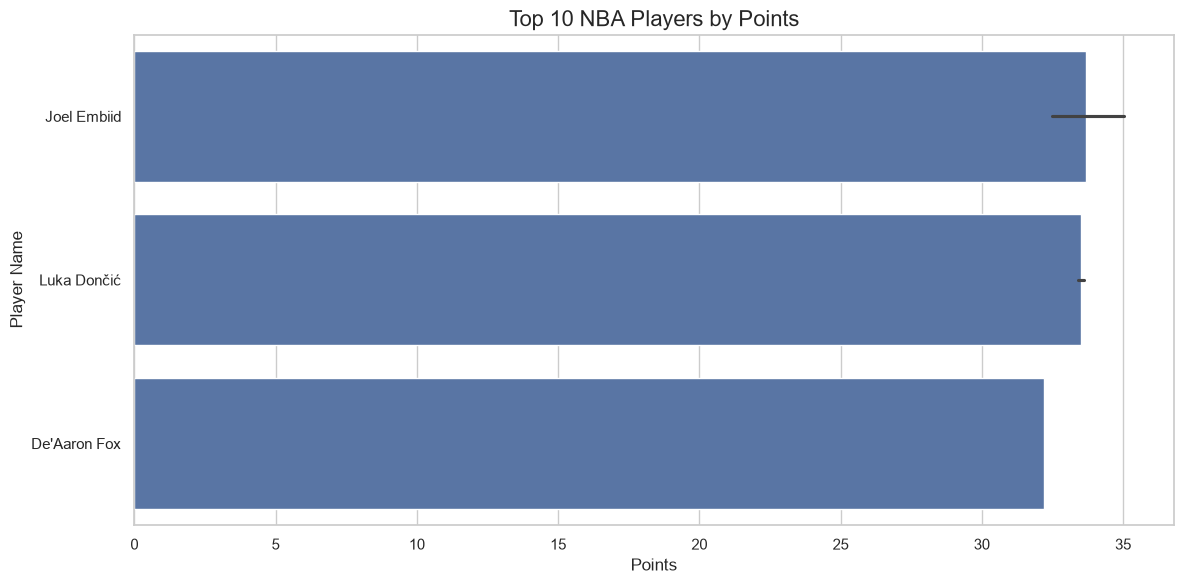

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Select the 10 players with the highest points
top_players = (
    df[["Player", "PTS"]]
    .dropna()
    .sort_values(by="PTS", ascending=False)
    .head(10)
)

# Create the chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_players,
    x="PTS",
    y="Player"
)

plt.title("Top 10 NBA Players by Points", fontsize=16)
plt.xlabel("Points")
plt.ylabel("Player Name")
plt.tight_layout()
plt.show()

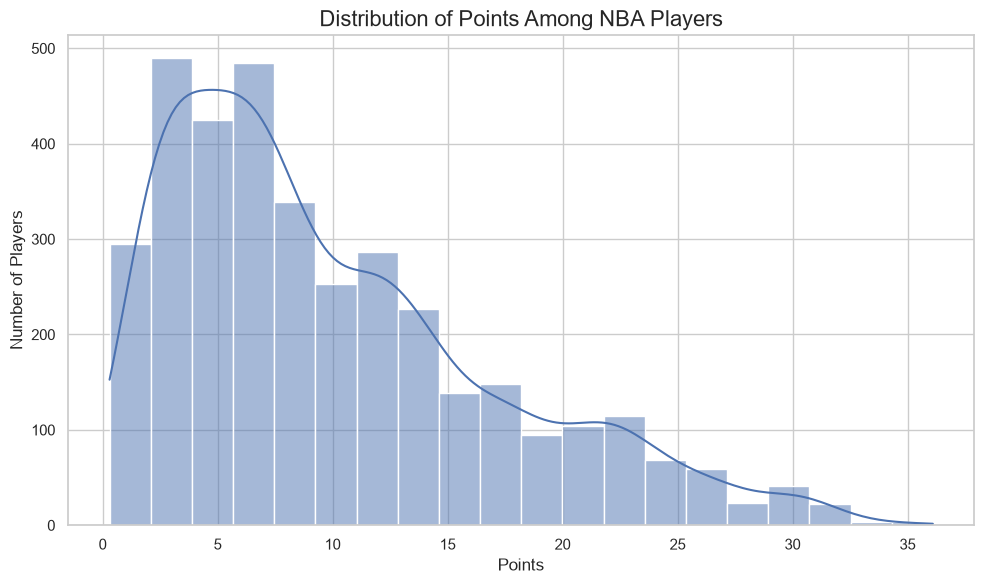

In [4]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="PTS",
    bins=20,
    kde=True
)

plt.title("Distribution of Points Among NBA Players", fontsize=16)
plt.xlabel("Points")
plt.ylabel("Number of Players")
plt.tight_layout()
plt.show()

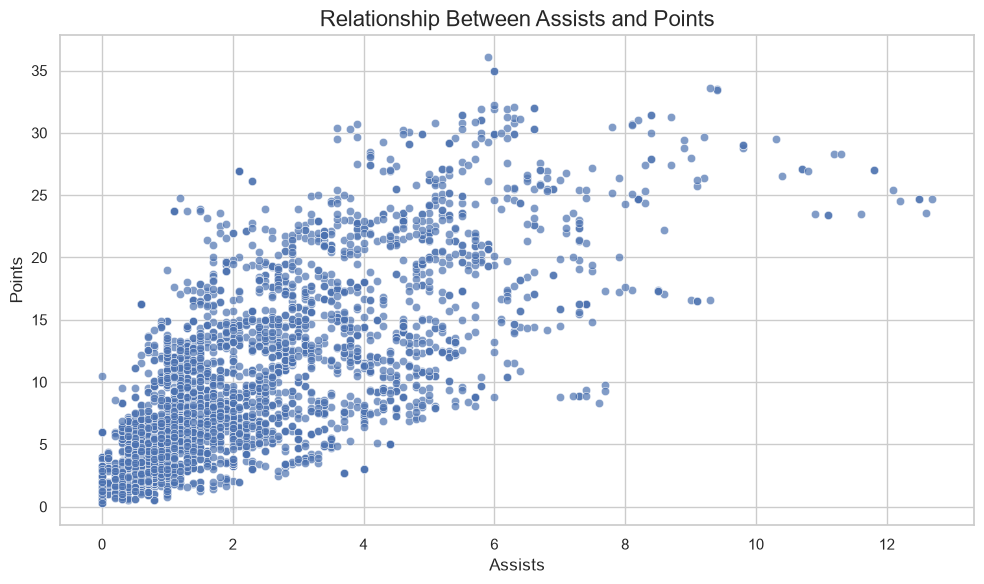

In [5]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="AST",
    y="PTS",
    alpha=0.7
)

plt.title("Relationship Between Assists and Points", fontsize=16)
plt.xlabel("Assists")
plt.ylabel("Points")
plt.tight_layout()
plt.show()


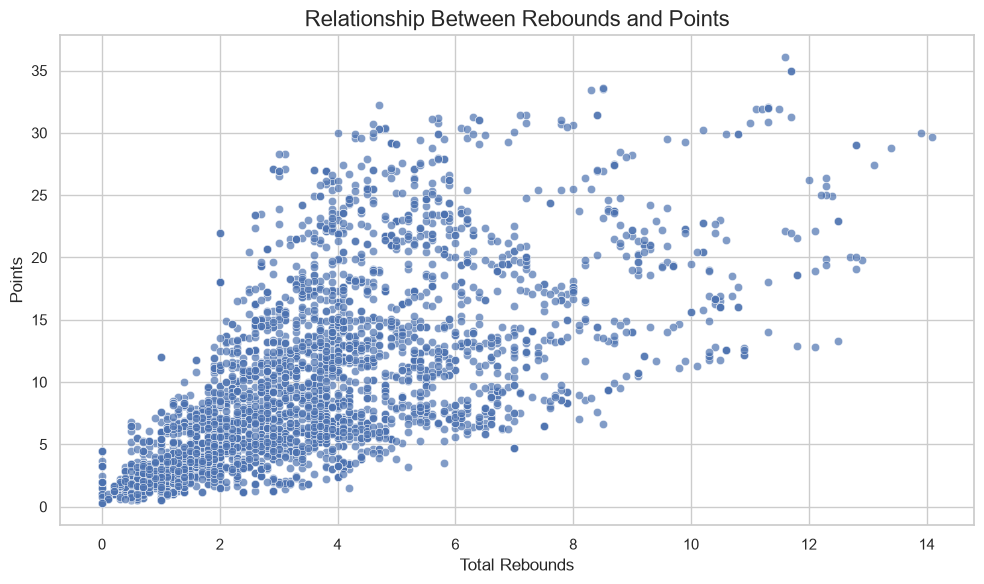

In [6]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="TRB",
    y="PTS",
    alpha=0.7
)

plt.title("Relationship Between Rebounds and Points", fontsize=16)
plt.xlabel("Total Rebounds")
plt.ylabel("Points")
plt.tight_layout()
plt.show()


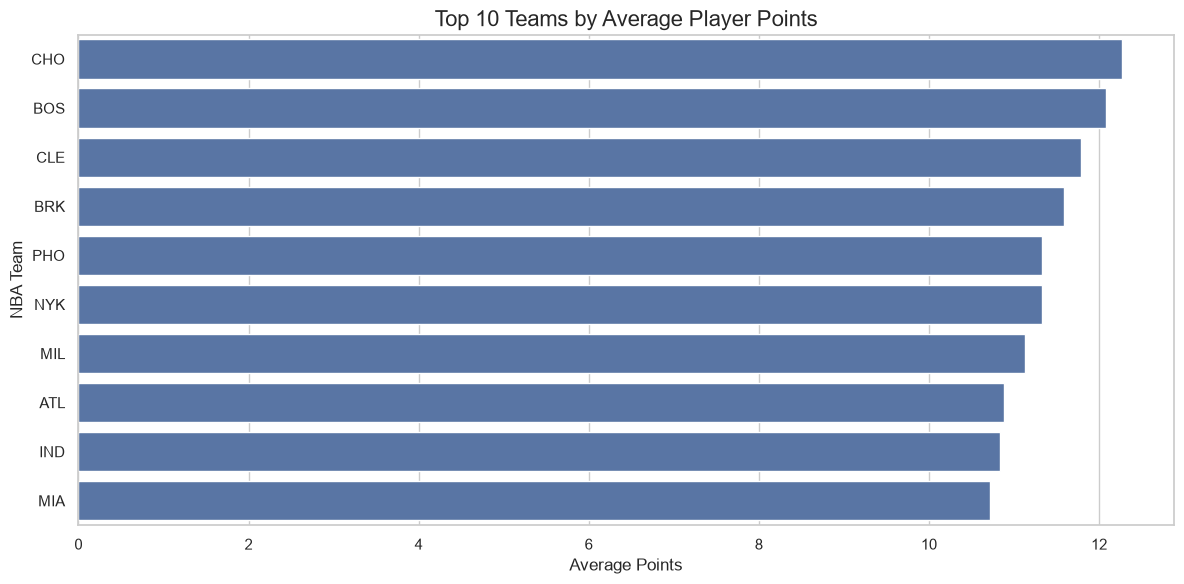

In [7]:

# Calculate average points for each team
team_scoring = (
    df.dropna(subset=["Tm", "PTS"])
    .groupby("Tm")["PTS"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

team_scoring.columns = ["Team", "Average Points"]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=team_scoring,
    x="Average Points",
    y="Team"
)

plt.title("Top 10 Teams by Average Player Points", fontsize=16)
plt.xlabel("Average Points")
plt.ylabel("NBA Team")
plt.tight_layout()
plt.show()


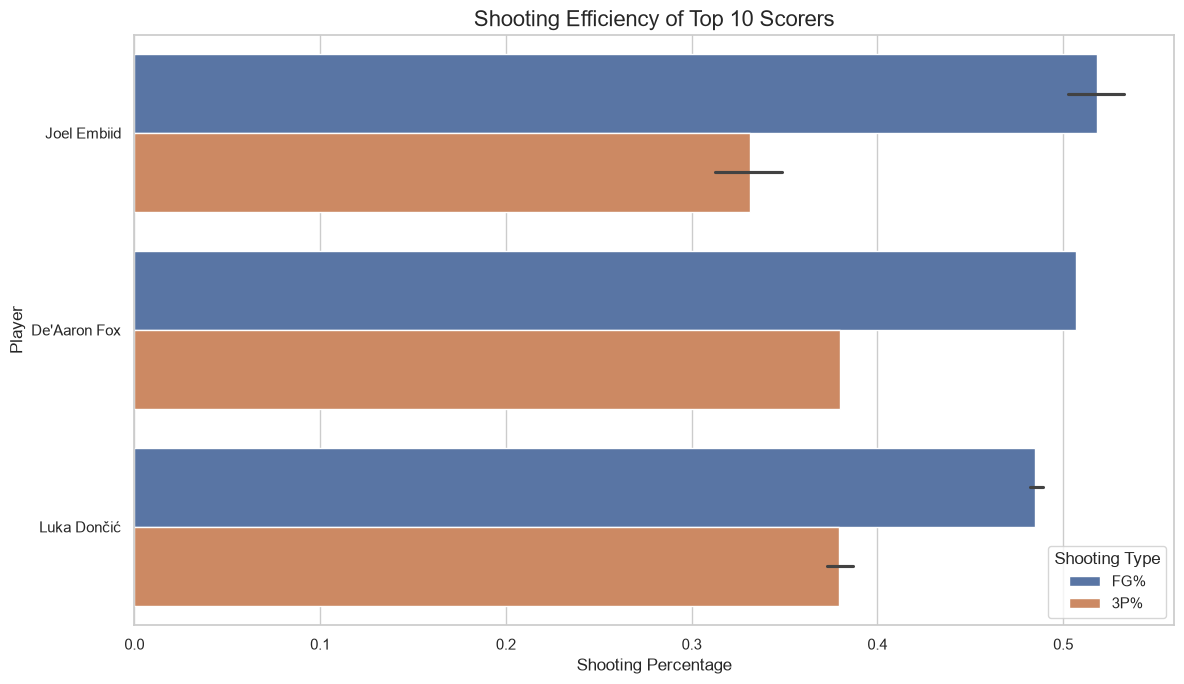

In [8]:

# Select the top 10 players by points
shooting_data = (
    df[["Player", "PTS", "FG%", "3P%"]]
    .dropna(subset=["Player", "PTS", "FG%", "3P%"])
    .sort_values("PTS", ascending=False)
    .head(10)
    .sort_values("PTS", ascending=True)
)

# Prepare shooting percentages for comparison
shooting_comparison = shooting_data.melt(
    id_vars="Player",
    value_vars=["FG%", "3P%"],
    var_name="Shooting Type",
    value_name="Percentage"
)

# Create the chart
plt.figure(figsize=(12, 7))

sns.barplot(
    data=shooting_comparison,
    x="Percentage",
    y="Player",
    hue="Shooting Type"
)

plt.title("Shooting Efficiency of Top 10 Scorers", fontsize=16)
plt.xlabel("Shooting Percentage")
plt.ylabel("Player")
plt.legend(title="Shooting Type")
plt.tight_layout()
plt.show()


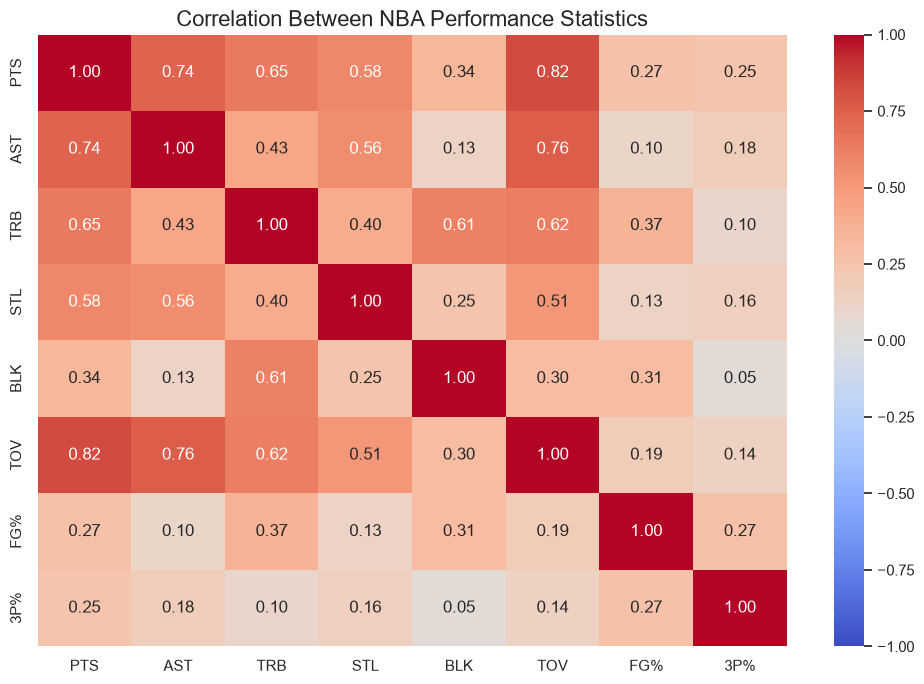

In [9]:


stats = ["PTS", "AST", "TRB", "STL", "BLK", "TOV", "FG%", "3P%"]


correlation_matrix = df[stats].corr(numeric_only=True)


plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Between NBA Performance Statistics", fontsize=16)
plt.tight_layout()
plt.show()


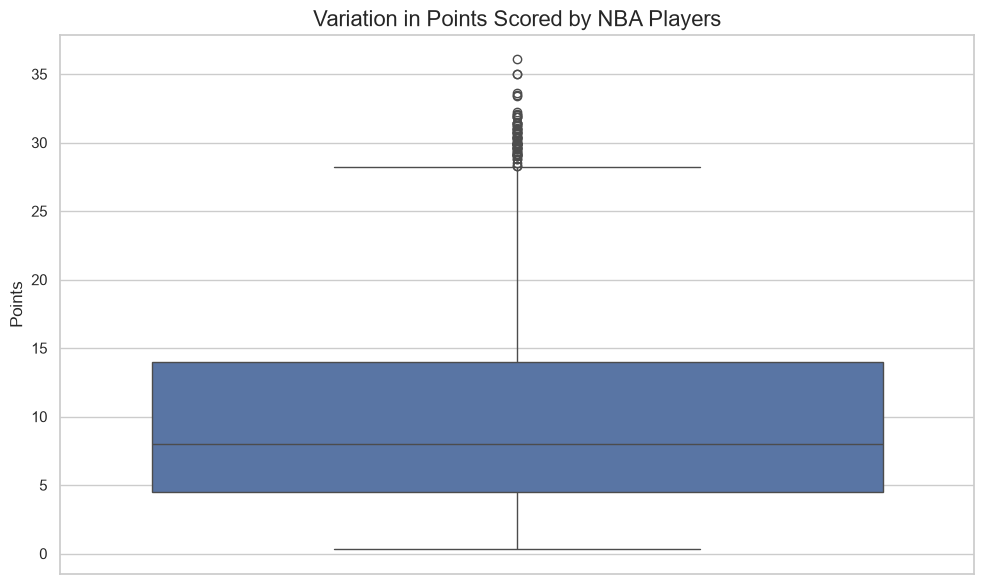

In [10]:

plt.figure(figsize=(10, 6))

sns.boxplot(
    y=df["PTS"].dropna()
)

plt.title("Variation in Points Scored by NBA Players", fontsize=16)
plt.ylabel("Points")
plt.tight_layout()
plt.show()



## Final Conclusions

### What I Learned

- The top-scoring players can be identified using a bar chart.
- A histogram helps explain how scoring values are distributed among players.
- Scatter plots help explore relationships between points, assists, and rebounds.
- Team-level comparisons can reveal differences in the average scoring of players.
- Shooting percentages help compare field-goal and three-point efficiency.
- A correlation heatmap summarizes relationships between multiple performance statistics.
- A box plot helps identify the median, spread, and unusual values in scoring data.

### Project Limitations

- This project uses the available dataset and its recorded statistics.
- A statistical relationship does not necessarily mean one factor causes another.
- Team comparisons based on average player points do not represent total team scoring.
- Results depend on the quality and structure of the source data.

### Final Reflection

This project helped me practice using Python, Pandas, Matplotlib, and Seaborn to turn sports statistics into meaningful visualizations. I learned how different chart types can answer different questions and how visual evidence can support data-driven conclusions.

### Dataset Source

NBA player statistics for the 2023–2024 season.
